In [1]:
import re
import numpy as np
from scipy.special import erf
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme( style="darkgrid" )

In [ ]:
# fileName = "scan1D-26AGO2026-32_25.txt"
# fileName = "scan1D-26AGO2026-32_0.txt"
# fileName = "scan1D-26AGO2026-32_1.txt"
# fileName = "scan1D-26AGO2026-32_2.txt"
# fileName = "scan1D-26AGO2026-32_4.txt"

# fileName = "scan1D-28AGO2026-32_3.txt"
# fileName = "scan1D-28AGO2026-32_4.txt"
# fileName = "scan1D-28AGO2026-32_5.txt"
# fileName = "scan1D-28AGO2026-32_6.txt"
# fileName = "scan1D-28AGO2026-32_7.txt"

# fileNames = [
#     "scan1D-14SEP2026-23_40.txt",
#     "scan1D-14SEP2026-23_60.txt",
#     "scan1D-14SEP2026-23_80.txt",
#     "scan1D-14SEP2026-23_90.txt",
#     "scan1D-14SEP2026-24_00.txt",
#     "scan1D-14SEP2026-24_10.txt",
#     "scan1D-14SEP2026-24_20.txt",
#     "scan1D-14SEP2026-24_30.txt",
#     "scan1D-14SEP2026-24_40.txt",
#     "scan1D-14SEP2026-24_50.txt",
#     "scan1D-14SEP2026-24_60.txt"
# ]
fileNames = [
    "scan1D-16SEP2026-18_25.txt"
    ]


In [131]:
scan_arr = []
step = None
arr = None
for fileName in fileNames:
    with open( fileName, 'r' ) as file_:
        while ( line_ := file_.readline() ) != "":
            p_ = re.compile( 'Step = *' )
            m_ = p_.match( line_ )
            if m_:
                step = float( line_[ m_.end() : ].replace( ',', '.' ) )
                break
        print( "step = {}".format( step ) )
        # arr = np.loadtxt( file_, skiprows=2 )
        arr = np.loadtxt( file_ )
        arr = (-1)*arr
    print ( arr )
    scan_arr.append( arr )
scan_arr

step = 0.01
[111. 112. 110. 111. 111. 110. 111. 113. 189. 282. 334. 371. 387. 414.
 428. 439.]
step = 0.01
[112. 112. 112. 112. 112. 112. 112. 115. 222. 339. 389. 427. 467. 482.
 496. 506.]
step = 0.01
[111. 110. 111. 110. 111. 109. 109. 134. 291. 400. 455. 496. 502. 540.
 561. 573.]
step = 0.01
[110. 110. 110. 110. 110. 110. 129. 244. 367. 443. 512. 504. 553. 555.
 572. 533.]
step = 0.01
[110. 109. 109. 110. 110. 110. 134. 246. 386. 462. 552. 560. 602. 602.
 616. 581.]
step = 0.01
[110. 110. 110. 110. 110. 113. 185. 284. 403. 502. 552. 591. 618. 662.
 628. 535.]
step = 0.01
[110. 110. 109. 109. 110. 116. 199. 290. 403. 518. 600. 625. 662. 667.
 674. 550.]
step = 0.01
[110. 110. 110. 110. 113. 187. 277. 381. 495. 561. 627. 673. 737. 722.
 646. 552.]
step = 0.01
[110. 110. 109. 110. 132. 227. 310. 395. 503. 582. 651. 696. 742. 720.
 607. 533.]
step = 0.01
[110. 110. 110. 127. 219. 277. 368. 450. 527. 590. 647. 685. 697. 632.
 544. 485.]
step = 0.01
[110. 110. 114. 186. 256. 322. 391. 46

[array([111., 112., 110., 111., 111., 110., 111., 113., 189., 282., 334.,
        371., 387., 414., 428., 439.]),
 array([112., 112., 112., 112., 112., 112., 112., 115., 222., 339., 389.,
        427., 467., 482., 496., 506.]),
 array([111., 110., 111., 110., 111., 109., 109., 134., 291., 400., 455.,
        496., 502., 540., 561., 573.]),
 array([110., 110., 110., 110., 110., 110., 129., 244., 367., 443., 512.,
        504., 553., 555., 572., 533.]),
 array([110., 109., 109., 110., 110., 110., 134., 246., 386., 462., 552.,
        560., 602., 602., 616., 581.]),
 array([110., 110., 110., 110., 110., 113., 185., 284., 403., 502., 552.,
        591., 618., 662., 628., 535.]),
 array([110., 110., 109., 109., 110., 116., 199., 290., 403., 518., 600.,
        625., 662., 667., 674., 550.]),
 array([110., 110., 110., 110., 113., 187., 277., 381., 495., 561., 627.,
        673., 737., 722., 646., 552.]),
 array([110., 110., 109., 110., 132., 227., 310., 395., 503., 582., 651.,
        696., 

In [132]:
nX = scan_arr[0].size
print ( nX )
X = np.arange(0, nX, 1) * step
print ( X )

16
[0.   0.01 0.02 0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13
 0.14 0.15]


In [133]:
#define a função para o ajuste de curva
def rise_function(x, sigma, x0, I, C):
    return 0.5*I*(1+erf((x-x0)/(np.sqrt(2)*sigma))) + C

[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[111. 111. 110. 111. 113. 189. 282. 334. 371. 387. 414.]


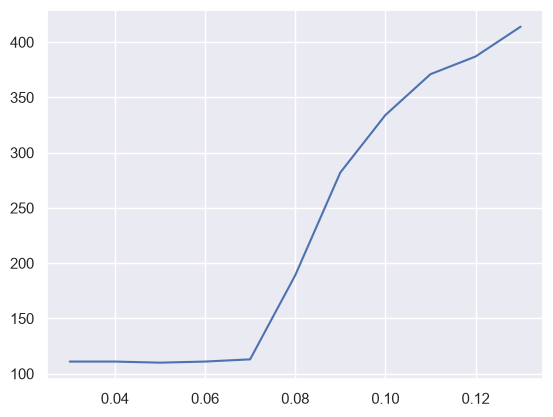

In [134]:
#definição do intervalo em que ocorre a subida
inf_lim = 0.02
sup_lim = 0.14

x_data = X[ ( X > inf_lim ) & ( X < sup_lim ) ]
y_data = scan_arr[0][ ( X > inf_lim ) & ( X < sup_lim ) ]
print ( x_data )
print ( y_data )
plt.plot(x_data, y_data)
plt.show()

[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[111. 111. 110. 111. 113. 189. 282. 334. 371. 387. 414.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[112. 112. 112. 112. 115. 222. 339. 389. 427. 467. 482.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 111. 109. 109. 134. 291. 400. 455. 496. 502. 540.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 110. 110. 129. 244. 367. 443. 512. 504. 553. 555.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 110. 110. 134. 246. 386. 462. 552. 560. 602. 602.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 110. 113. 185. 284. 403. 502. 552. 591. 618. 662.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[109. 110. 116. 199. 290. 403. 518. 600. 625. 662. 667.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 113. 187. 277. 381. 495. 561. 627. 673. 737. 722.]
[0.03 0.04 0.05 0.06 0.07 0.08 0.09 0.1  0.11 0.12 0.13]
[110. 132. 227. 310. 395. 503. 

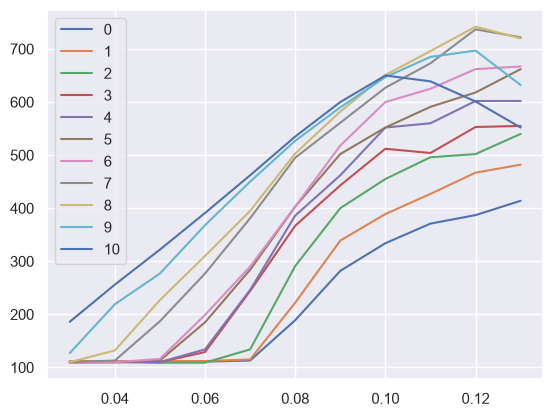

In [ ]:
for idx in range( len(scan_arr) ):
    x_data = X[ ( X > inf_lim ) & ( X < sup_lim ) ]
    y_data = scan_arr[idx][ ( X > inf_lim ) & ( X < sup_lim ) ]
    print ( x_data )
    print ( y_data )
    plt.plot( x_data, y_data, label="{}".format(idx) )
plt.legend()


[1.33362948e-02 8.80805642e-02 2.89979846e+02 1.06583283e+02]
sigma=0.01333629478415018


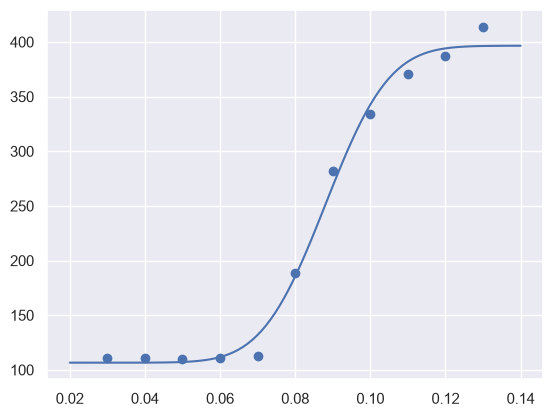

In [137]:
# AJUSTE DE CURVA
# Valores iniciais dos parâmentros
p0 = [0.01, 0.08, 400, 100]

x_data = X[ ( X > inf_lim ) & ( X < sup_lim ) ]
y_data = scan_arr[0][ ( X > inf_lim ) & ( X < sup_lim ) ]
popt, pcov = curve_fit(rise_function, x_data, y_data, p0)

print(popt)
sig, x0, I, C= popt

plt.scatter(x_data, y_data)
X_ = np.linspace(inf_lim,sup_lim,100)
yopt = rise_function(X_, sig, x0, I, C)
plt.plot(X_, yopt)
print("sigma={}".format(sig) )

[1.33362948e-02 8.80805642e-02 2.89979846e+02 1.06583283e+02]
sigma=0.01333629478415018
[1.34371170e-02 8.69569973e-02 3.58544485e+02 1.06039099e+02]
sigma=0.013437117031989017
[1.19886579e-02 8.29431993e-02 4.05746608e+02 1.04073873e+02]
sigma=0.011988657903280102
[1.44040866e-02 7.73255439e-02 4.36809934e+02 1.01612285e+02]
sigma=0.014404086583896001
[1.53602435e-02 7.86184593e-02 4.91079207e+02 1.00476218e+02]
sigma=0.015360243469357599
[1.94026537e-02 7.76506216e-02 5.43001949e+02 9.24054179e+01]
sigma=0.019402653660521102
[1.85875299e-02 7.79787359e-02 5.66204646e+02 9.73409183e+01]
sigma=0.018587529932580216
[2.61846082e-02 7.20097078e-02 6.79483760e+02 5.66576800e+01]
sigma=0.026184608223241885
[2.74241508e-02 6.96173703e-02 6.93041465e+02 5.19875026e+01]
sigma=0.02742415077711803
[2.69020674e-02 6.03230522e-02 6.20188340e+02 5.98720904e+01]
sigma=0.026902067380990366
[1.99336082e-02 5.94138321e-02 4.43526547e+02 1.68715881e+02]
sigma=0.01993360824024783


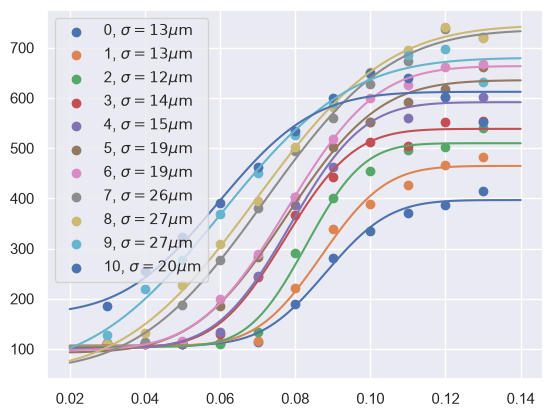

In [144]:
p0 = [0.01, 0.08, 400, 100]
for idx in range( len(scan_arr) ):
    x_data = X[ ( X > inf_lim ) & ( X < sup_lim ) ]
    y_data = scan_arr[idx][ ( X > inf_lim ) & ( X < sup_lim ) ]
    popt, pcov = curve_fit(rise_function, x_data, y_data, p0)

    print(popt)
    sig, x0, I, C= popt
    plt.scatter(x_data, y_data, label="{}, {}".format( idx, r'$\sigma={:.0f}\mu\rm{{m}}$'.format(sig*1e+03) ))
    X_ = np.linspace(inf_lim,sup_lim,100)
    yopt = rise_function(X_, sig, x0, I, C)
    plt.plot(X_, yopt)
    print("sigma={}".format(sig) )
plt.legend()